      QUANTUM METROLOGY ENGINE: DUAL KRAUS ADJOINT LOCKED MAP
[+] Active Channels (N): 3 | Hilbert Dimension: 8
[+] Operational Sequence Sequence: [Evolution] -> [Parameter Encoding] -> [Kraus Noise]
------------------------------------------------------------------------------
[✓] N=1 Analytical Check at p=0.25:
    Numerical Engine QFI: 0.750000 | Analytical Theory: 0.750000
    Validation Discrepancy Delta: 5.55e-16
------------------------------------------------------------------------------

[⏱️ TIME STEP 0 | t = 0.00s | p_damping = 0.0000]
  ▪️ Product State (|+>^N):
    -> Schrödinger Picture QFI  | Ideal: 3.00000  | Noisy: 3.00000
    -> Heisenberg Picture QFI   | Ideal: 3.00000  | Noisy: 3.00000
    [Verification] Ideal picture equivalency delta: 0.000e+00
    [Verification] Noisy picture equivalency delta: 0.000e+00
    [Diagnostics] Physical Noise Degradation      : 0.00%
  ▪️ Entangled GHZ State:
    -> Schrödinger Picture QFI  | Ideal: 9.00000  | Noisy: 9.00000
    -> Hei

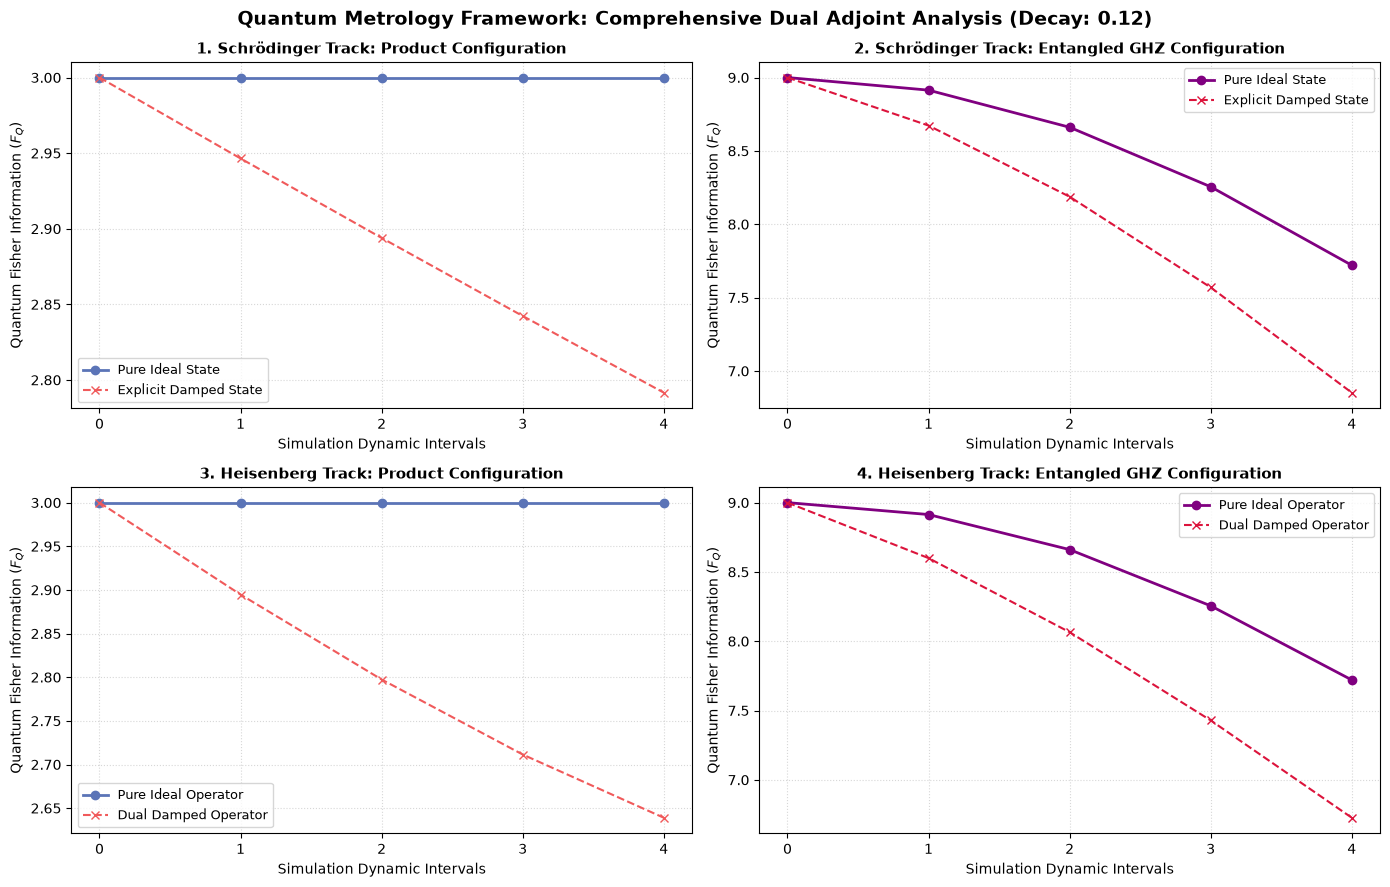

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg

# ============================================================================
# 1. Generalized Quantum Fisher Information (QFI) Mixed-State Engine
# ============================================================================

def verify_physical_state(rho, atol=1e-8):
    """
    Rigorously verify if the matrix represents a valid physical density matrix.
    Asserts: Trace == 1.0, Hermiticity (rho == rho^dagger), and Positive Semi-Definiteness.
    """
    if not np.all(np.isfinite(rho)):
        raise ValueError("Density matrix contains non-finite values.")
    if not np.isclose(np.trace(rho).real, 1.0, atol=atol):
        raise ValueError(f"Physical state failure: Trace must be 1.0, got {np.trace(rho):.6f}")
    if not np.allclose(rho, rho.conj().T, atol=atol):
        raise ValueError("Physical state failure: Matrix must be Hermitian (rho == rho^dagger).")
    eigenvalues = np.linalg.eigvalsh(rho)
    if np.any(eigenvalues < -atol):
        raise ValueError(f"Physical state failure: Negative eigenvalues detected: {eigenvalues}")

def compute_generalized_mixed_qfi(rho, d_rho_matrix, tol=1e-10):
    """
    Generalized QFI Engine for Mixed States via Spectral SLD Decomposition.
    Ingests the density matrix (rho) and its explicit parameter derivative matrix (d_rho).
    Solves the Lyapunov Symmetric Logarithmic Derivative (SLD) equation:
        L_SLD * rho + rho * L_SLD = 2 * d(rho)/d(theta)
    """
    rho = np.asarray(rho, dtype=complex)
    d_rho = np.asarray(d_rho_matrix, dtype=complex)
    
    verify_physical_state(rho, atol=tol)
    if d_rho.shape != rho.shape:
        raise ValueError("Explicit derivative matrix and density matrix dimensions must match.")
    if not np.allclose(d_rho, d_rho.conj().T, atol=tol):
        raise ValueError("Physical verification failure: Parameter derivative matrix must be Hermitian.")
        
    dim = rho.shape[0]
    p, v = np.linalg.eigh(rho)
    
    # Clip tiny negative eigenvalues caused by floating-point numerical round-off
    p = np.clip(p, 0.0, None)
    
    # Project the explicit derivative matrix into the eigenbasis of rho
    d_rho_eigen = v.conj().T @ d_rho @ v
    
    # Evaluate the Symmetric Logarithmic Derivative (SLD) matrix tensor sum
    qfi = 0.0
    for i in range(dim):
        for j in range(dim):
            denominator = p[i] + p[j]
            if denominator > 1e-12: # Guardrail against zero-eigenvalue singularities
                qfi += 2.0 * abs(d_rho_eigen[i, j]) ** 2 / denominator
                
    return max(0.0, float(np.real(qfi)))


# ============================================================================
# 2. Multi-Qubit Tensor-Product Expansion & Kraus Mapping Utilities
# ============================================================================

def tensor_product_operators(operators):
    """Recursively execute Kronecker product expansions across an array of local operators."""
    result = np.array([[1.0 + 0.0j]])
    for op in operators:
        result = np.kron(result, op)
    return result

def apply_kraus_channel(rho, kraus_ops):
    """Schrödinger Picture: Execute direct quantum channel trace mapping: rho -> sum_k E_k * rho * E_k^dagger."""
    result = np.zeros_like(rho, dtype=complex)
    for E in kraus_ops:
        result += E @ rho @ E.conj().T
    return 0.5 * (result + result.conj().T)

def apply_dual_kraus_map(generator_matrix, kraus_ops):
    """Heisenberg Picture: Execute dual adjoint quantum channel mapping: G -> sum_k E_k^dagger * G * E_k."""
    G_ideal = np.asarray(generator_matrix, dtype=complex)
    G_noisy = np.zeros_like(G_ideal, dtype=complex)
    for E_k in kraus_ops:
        G_noisy += E_k.conj().T @ G_ideal @ E_k
    return 0.5 * (G_noisy + G_noisy.conj().T)


# ============================================================================
# 3. Metrological Core Building Frameworks (States & Generators)
# ============================================================================

def build_initial_probe_density(n_qubits, entangled=False):
    """Construct initial state density matrix via pure NumPy Kronecker expansions."""
    state_0 = np.array([1.0, 0.0], dtype=complex)
    state_1 = np.array([0.0, 1.0], dtype=complex)
    state_plus = (state_0 + state_1) / np.sqrt(2.0)
    
    if not entangled:
        psi = state_plus
        for _ in range(n_qubits - 1):
            psi = np.kron(psi, state_plus)
    else:
        psi_00 = state_0
        psi_11 = state_1
        for _ in range(n_qubits - 1):
            psi_00 = np.kron(psi_00, state_0)
            psi_11 = np.kron(psi_11, state_1)
        psi = (psi_00 + psi_11) / np.sqrt(2.0)
        
    return np.outer(psi, psi.conj())

def build_amplitude_damping_kraus(n_qubits, p_damping):
    """Construct multi-qubit independent amplitude damping Kraus operators."""
    e0_local = np.array([[1.0, 0.0], [0.0, np.sqrt(1.0 - p_damping)]], dtype=complex)
    e1_local = np.array([[0.0, np.sqrt(p_damping)], [0.0, 0.0]], dtype=complex)
    
    global_kraus_list = []
    for mask in range(2 ** n_qubits):
        operators = []
        for qubit in range(n_qubits):
            bit = (mask >> qubit) & 1
            operators.append(e1_local if bit == 1 else e0_local)
        global_kraus_list.append(tensor_product_operators(operators))
    return global_kraus_list

def build_base_generator(n_qubits):
    """Build collective parameter encoding generator matrix: G = 0.5 * Sum_i Z_i"""
    identity = np.eye(2, dtype=complex)
    pauli_z = np.array([[1.0, 0.0], [0.0, -1.0]], dtype=complex)
    dim = 2 ** n_qubits
    generator = np.zeros((dim, dim), dtype=complex)

    for i in range(n_qubits):
        operators = [identity.copy() for _ in range(n_qubits)]
        operators[i] = pauli_z
        generator += 0.5 * tensor_product_operators(operators)
    return generator

def run_single_qubit_analytical_check(p_damping):
    """Perform validation for N=1 qubit under amplitude damping: theory QFI = 1 - p."""
    rho_0 = build_initial_probe_density(1, entangled=False)
    kraus_ops = build_amplitude_damping_kraus(1, p_damping)
    rho_damped = apply_kraus_channel(rho_0, kraus_ops)
    g_single = 0.5 * np.array([[1.0, 0.0], [0.0, -1.0]], dtype=complex) 
    
    d_rho_single = -1j * (g_single @ rho_damped - rho_damped @ g_single)
    qfi_numerical = compute_generalized_mixed_qfi(rho_damped, d_rho_single)
    qfi_analytical = 1.0 - p_damping
    return qfi_numerical, qfi_analytical
def main():
    n_qubits = 3          
    time_steps = 5        
    dt = 0.15             
    gamma_leakage = 0.12  
    
    dim = 2 ** n_qubits
    G_0 = build_base_generator(n_qubits)
    
    identity = np.eye(2, dtype=complex)
    pauli_x = np.array([[0.0, 1.0], [1.0, 0.0]], dtype=complex)
    H_matrix = np.zeros((dim, dim), dtype=complex)
    for i in range(n_qubits):
        operators = [identity.copy() for _ in range(n_qubits)]
        operators[i] = pauli_x
        H_matrix += 0.4 * tensor_product_operators(operators)

    results = {
        'schrodinger_product_ideal': [], 'schrodinger_product_noisy': [],
        'schrodinger_ghz_ideal':     [], 'schrodinger_ghz_noisy':     [],
        'heisenberg_product_ideal':  [], 'heisenberg_product_noisy':  [],
        'heisenberg_ghz_ideal':      [], 'heisenberg_ghz_noisy':      []
    }
    
    steps_range = np.arange(time_steps)

    print("=" * 78)
    print("      QUANTUM METROLOGY ENGINE: DUAL KRAUS ADJOINT LOCKED MAP")
    print("=" * 78)
    print(f"[+] Active Channels (N): {n_qubits} | Hilbert Dimension: {dim}")
    print(f"[+] Operational Sequence Sequence: [Evolution] -> [Parameter Encoding] -> [Kraus Noise]")
    print("-" * 78)

    # Validate engine tracking baseline accuracy
    p_check = 0.25
    num_check, ana_check = run_single_qubit_analytical_check(p_check)
    print(f"[✓] N=1 Analytical Check at p={p_check}:")
    print(f"    Numerical Engine QFI: {num_check:.6f} | Analytical Theory: {ana_check:.6f}")
    print(f"    Validation Discrepancy Delta: {abs(num_check - ana_check):.2e}")
    print("-" * 78)

    for step in range(time_steps):
        t = step * dt
        p_damping = 1.0 - np.exp(-gamma_leakage * t)
        kraus_ops = build_amplitude_damping_kraus(n_qubits, p_damping)
        
        assert np.allclose(sum(E.conj().T @ E for E in kraus_ops), np.eye(dim), atol=1e-10)
        
        U_t = scipy.linalg.expm(-1j * H_matrix * t)
        U_t_dagger = U_t.conj().T
        
        print(f"\n[⏱️ TIME STEP {step} | t = {t:.2f}s | p_damping = {p_damping:.4f}]")
        
        for entangled_mode in [False, True]:
            state_key = 'ghz' if entangled_mode else 'product'
            state_name = "Entangled GHZ State" if entangled_mode else "Product State (|+>^N)"
            rho_0 = build_initial_probe_density(n_qubits, entangled=entangled_mode)
            
            # --- Schrödinger Framework: direct matrix evolution ---
            rho_t_ideal = U_t @ rho_0 @ U_t_dagger
            d_rho_s_ideal = -1j * (G_0 @ rho_t_ideal - rho_t_ideal @ G_0)
            qfi_s_ideal = compute_generalized_mixed_qfi(rho_t_ideal, d_rho_s_ideal)
            results[f'schrodinger_{state_key}_ideal'].append(qfi_s_ideal)
            
            rho_t_noisy = apply_kraus_channel(rho_t_ideal, kraus_ops)
            d_rho_s_noisy = apply_kraus_channel(d_rho_s_ideal, kraus_ops) # Explicit noisy derivative map
            qfi_s_noisy = compute_generalized_mixed_qfi(rho_t_noisy, d_rho_s_noisy)
            results[f'schrodinger_{state_key}_noisy'].append(qfi_s_noisy)
            
            # --- Heisenberg Framework: dual adjoint operator evolution ---
            G_t_ideal = U_t_dagger @ G_0 @ U_t
            d_rho_h_ideal = -1j * (G_t_ideal @ rho_0 - rho_0 @ G_t_ideal)
            qfi_h_ideal = compute_generalized_mixed_qfi(rho_0, d_rho_h_ideal)
            results[f'heisenberg_{state_key}_ideal'].append(qfi_h_ideal)
            
            # Non-Unitary Heisenberg tracking via explicit Dual Kraus Adjoint Map mapping
            G_t_noisy = apply_dual_kraus_map(G_t_ideal, kraus_ops)
            d_rho_h_noisy = -1j * (G_t_noisy @ rho_0 - rho_0 @ G_t_noisy) # Exact open derivative tracking
            qfi_h_noisy = compute_generalized_mixed_qfi(rho_0, d_rho_h_noisy)
            results[f'heisenberg_{state_key}_noisy'].append(qfi_h_noisy)
            
            ideal_delta = abs(qfi_s_ideal - qfi_h_ideal)
            noisy_delta = abs(qfi_s_noisy - qfi_h_noisy)
            loss_pct = ((qfi_s_ideal - qfi_s_noisy) / qfi_s_ideal) * 100 if qfi_s_ideal > 0 else 0
            
            print(f"  ▪️ {state_name}:")
            print(f"    -> Schrödinger Picture QFI  | Ideal: {qfi_s_ideal:.5f}  | Noisy: {qfi_s_noisy:.5f}")
            print(f"    -> Heisenberg Picture QFI   | Ideal: {qfi_h_ideal:.5f}  | Noisy: {qfi_h_noisy:.5f}")
            print(f"    [Verification] Ideal picture equivalency delta: {ideal_delta:.3e}")
            print(f"    [Verification] Noisy picture equivalency delta: {noisy_delta:.3e}")
            print(f"    [Diagnostics] Physical Noise Degradation      : {loss_pct:.2f}%")

    print("\n" + "=" * 78)
    print("[+] Audited Dual Simulation Complete. Rendering Analytical Graphs...")
    print("=" * 78)

    fig, axs = plt.subplots(2, 2, figsize=(14, 9))
    fig.suptitle(f"Quantum Metrology Framework: Comprehensive Dual Adjoint Analysis (Decay: {gamma_leakage})", fontsize=14, fontweight='bold')
    
    # 1. Schrödinger Product Track
    axs[0, 0].plot(steps_range, results['schrodinger_product_ideal'], 'o-', color='#5B74B7', linewidth=2, label='Pure Ideal State')
    axs[0, 0].plot(steps_range, results['schrodinger_product_noisy'], 'x--', color='#F05A5B', linewidth=1.5, label='Explicit Damped State')
    axs[0, 0].set_title("1. Schrödinger Track: Product Configuration", fontsize=11, fontweight='bold')
    
    # 2. Schrödinger GHZ Track
    axs[0, 1].plot(steps_range, results['schrodinger_ghz_ideal'], 'o-', color='purple', linewidth=2, label='Pure Ideal State')
    axs[0, 1].plot(steps_range, results['schrodinger_ghz_noisy'], 'x--', color='crimson', linewidth=1.5, label='Explicit Damped State')
    axs[0, 1].set_title("2. Schrödinger Track: Entangled GHZ Configuration", fontsize=11, fontweight='bold')
    
    # 3. Heisenberg Product Track (NOW WITH DUAL ADJOINT NOISE TRAJECTORY!)
    axs[1, 0].plot(steps_range, results['heisenberg_product_ideal'], 'o-', color='#5B74B7', linewidth=2, label='Pure Ideal Operator')
    axs[1, 0].plot(steps_range, results['heisenberg_product_noisy'], 'x--', color='#F05A5B', linewidth=1.5, label='Dual Damped Operator')
    axs[1, 0].set_title("3. Heisenberg Track: Product Configuration", fontsize=11, fontweight='bold')
    
    # 4. Heisenberg GHZ Track (NOW WITH DUAL ADJOINT NOISE TRAJECTORY!)
    axs[1, 1].plot(steps_range, results['heisenberg_ghz_ideal'], 'o-', color='purple', linewidth=2, label='Pure Ideal Operator')
    axs[1, 1].plot(steps_range, results['heisenberg_ghz_noisy'], 'x--', color='crimson', linewidth=1.5, label='Dual Damped Operator')
    axs[1, 1].set_title("4. Heisenberg Track: Entangled GHZ Configuration", fontsize=11, fontweight='bold')
    
    for ax in axs.flat:
        ax.set_xlabel("Simulation Dynamic Intervals")
        ax.set_ylabel("Quantum Fisher Information ($F_Q$)")
        ax.set_xticks(steps_range)
        ax.grid(True, linestyle=':', alpha=0.5)
        ax.legend(loc='best', fontsize=9)
        ax.set_axisbelow(True)
        
    plt.tight_layout()
    plt.savefig("quantum_metrology_dual_adjoint_analysis.png", dpi=300, bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    main()
